# Exploratory Data Analysis (EDA) — Diabetes Health Indicators

This notebook investigates the **Diabetes Health Indicators** dataset from the CDC's *Behavioral Risk Factor
Surveillance System* (BRFSS) 2015 survey. We explore how diabetes status relates to **health conditions**
(blood pressure, cholesterol, BMI, heart disease), **lifestyle** (smoking, physical activity, diet, alcohol),
**healthcare access**, and **demographics** (sex, age, education, income) before any modelling is done.

**Source:** [Kaggle — Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset/data)

## 1. Library Setup

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import plotly.graph_objects as go
import plotly.express as px

try:
    from ydata_profiling import ProfileReport
except ImportError:
    ProfileReport = None
    print("ydata_profiling is not installed - ProfileReport is unavailable.")

plt.rcParams["figure.figsize"] = (9, 4)

## 2. Data Description and Loading

The Kaggle dataset contains three CSV files, all derived from the BRFSS 2015 survey:

| File | Rows | Variable of interest |
|---|---|---|
| `diabetes_012_health_indicators_BRFSS2015.csv` | 253,680 | `Diabetes_012`: 0 = no diabetes, 1 = prediabetes, 2 = diabetes |
| `diabetes_binary_health_indicators_BRFSS2015.csv` | 253,680 | `Diabetes_binary`: 0 = no diabetes, 1 = prediabetes or diabetes |
| `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` | 70,692 | `Diabetes_binary`, balanced 50/50 between the two classes |

We use the **full three-class file** (`diabetes_012`), because it is the most complete version of the data.
Each row is **one survey respondent**. All values are stored as floats in the CSV, but every column holds whole
numbers (codes or counts), so we convert them to integers to make the tables and report easier to read.

In [14]:
# Path is relative to this notebook (ml/notebooks) -> project root -> data/raw_data
csv_path = Path("../../data/raw_data/diabetes_012_health_indicators_BRFSS2015.csv")

df = pd.read_csv(csv_path)
df = df.astype(int)

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
display(df.head())

Rows: 253680, Columns: 22


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


## 3. Feature Description

| Group | Variable | Description |
|---|---|---|
| **Variable of interest** | `Diabetes_012` | 0 = no diabetes (or only during pregnancy), 1 = prediabetes, 2 = diabetes |
| **Health conditions** | `HighBP` | Ever told by a health professional they have high blood pressure (0 = no, 1 = yes) |
| | `HighChol` | Ever told they have high blood cholesterol (0 = no, 1 = yes) |
| | `CholCheck` | Cholesterol check within the past 5 years (0 = no, 1 = yes) |
| | `BMI` | Body Mass Index (kg/m²) |
| | `Stroke` | Ever told they had a stroke (0 = no, 1 = yes) |
| | `HeartDiseaseorAttack` | Coronary heart disease or heart attack (0 = no, 1 = yes) |
| | `DiffWalk` | Serious difficulty walking or climbing stairs (0 = no, 1 = yes) |
| **Lifestyle** | `Smoker` | Smoked at least 100 cigarettes in their entire life (0 = no, 1 = yes) |
| | `PhysActivity` | Physical activity in the past 30 days, not including job (0 = no, 1 = yes) |
| | `Fruits` | Eats fruit 1 or more times per day (0 = no, 1 = yes) |
| | `Veggies` | Eats vegetables 1 or more times per day (0 = no, 1 = yes) |
| | `HvyAlcoholConsump` | Heavy drinker: men ≥ 14 drinks/week, women ≥ 7 drinks/week (0 = no, 1 = yes) |
| **Self-rated health** | `GenHlth` | General health: 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor |
| | `MentHlth` | Days of poor mental health in the past 30 days (0–30) |
| | `PhysHlth` | Days of physical illness or injury in the past 30 days (0–30) |
| **Healthcare access** | `AnyHealthcare` | Has any kind of health care coverage (0 = no, 1 = yes) |
| | `NoDocbcCost` | Needed to see a doctor in the past 12 months but could not because of cost (0 = no, 1 = yes) |
| **Demographics** | `Sex` | 0 = female, 1 = male |
| | `Age` | 13-level age category: 1 = 18–24, 2 = 25–29, … (5-year steps) …, 12 = 75–79, 13 = 80 or older |
| | `Education` | 1 = never attended school / kindergarten only, 2 = grades 1–8, 3 = grades 9–11, 4 = high school graduate, 5 = some college, 6 = college graduate |
| | `Income` | Household income: 1 = less than \$10,000, 2 = \$10–15k, 3 = \$15–20k, 4 = \$20–25k, 5 = \$25–35k, 6 = \$35–50k, 7 = \$50–75k, 8 = \$75,000 or more |

> **Variable of interest:** `Diabetes_012` is the quantity we want to understand and later predict.
>
> Note that most columns are **codes**, not measurements: 14 are binary (0/1) and `GenHlth`, `Age`,
> `Education` and `Income` are **ordinal categories**. Only `BMI`, `MentHlth` and `PhysHlth` are true numbers.

## 4. Descriptive Statistics

Descriptive statistics summarise each column with a few numbers: the **count** of non-missing values, the
**mean** and **standard deviation** (centre and spread), the **minimum/maximum**, and the **quartiles**
(25%, 50% = median, 75%). Transposing the table puts one variable per row, which is easier to read.

For a binary 0/1 column the **mean is the share of respondents with value 1** — for example a mean of 0.43 for
`HighBP` means 43 % of respondents report high blood pressure.

In [15]:
display(df.describe(include='all').transpose())

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


## 5. Automated Exploratory Data Analysis Using YData Profiling

### 5.1 Introduction

**What is automated profiling?**
Automated profiling means letting a library inspect the whole dataset for us and produce a report. With a
single command we get an overview of every column: its type, missing values, distribution, extreme values,
correlations with other columns, and warnings about possible data problems.

**Why do we perform EDA before machine learning?**
A machine learning model can only be as good as the data it learns from. Before building a model we want to:
- understand what each variable means and what values it takes,
- find **errors** such as missing values, duplicates, or impossible numbers,
- see which variables seem **related** to the variable of interest (`Diabetes_012`),
- discover patterns (for example class imbalance or risk rising with age) that can guide feature engineering.

Skipping EDA often leads to models that are wrong for reasons that could have been spotted early.

**How does YData Profiling complement `df.describe()`?**
`df.describe()` gives us a compact table of numbers (mean, standard deviation, quartiles …). It is fast,
but it does not show pictures, missing-value patterns, correlations, or warnings. YData Profiling adds:
- histograms and value counts for each variable,
- missing-value charts,
- duplicate-row detection,
- correlation matrices between variables,
- automatic **alerts** (for example "high correlation", "imbalance" or "many zeros").

Think of `describe()` as a quick summary and the profiling report as an interactive, detailed health check.

### 5.2 The Library: `ProfileReport`

`ProfileReport` is the main class of the `ydata_profiling` package. We give it a pandas DataFrame and it
builds an HTML report describing the data.

It was already imported in **1. Library Setup** inside a `try/except ImportError` block. The cell below simply
checks whether the import worked.

**If `ProfileReport` is unavailable**, install the package yourself in a new cell (it is *not* installed
automatically here):

```python
%pip install ydata-profiling "setuptools==80.9.0"
```

After installing, **restart the notebook kernel** and re-run the library setup cell.

In [16]:
if ProfileReport is None:
    print("ProfileReport is not available. See the installation instructions above.")
else:
    print("ProfileReport is ready to use.")

ProfileReport is ready to use.


### 5.3 Generating the Report

The code cell below works like this:

| Code | What it does |
|---|---|
| `ProfileReport(df, title=...)` | Creates a profiling report object from our existing DataFrame `df`. The data is **not** changed. |
| `profile.to_file("Diabetes_EDA_Profile.html")` | Writes the report to an HTML file that can be opened in any web browser. |
| `profile` | Displays the report inside the notebook (Jupyter renders the object as an interactive widget). |

**Optional parameters you can add to `ProfileReport(...)`:**
- `explorative=True` — turns on extra, more detailed analyses (for example richer descriptions of text and
  date columns). Useful when you want to explore deeper.
- `minimal=True` — produces a **faster, lighter** report by switching off expensive computations. This is
  helpful on large datasets or slow computers, but **some advanced analyses (such as certain correlation
  calculations and interaction plots) may be missing** from the report.

Example: `ProfileReport(df, explorative=True, minimal=True)`.

> **Note:** This dataset has more than 250,000 rows, so generating the full report takes a few minutes.
> If it is too slow on your computer, try `minimal=True` first.

In [17]:
profile = ProfileReport(df, title="Diabetes Health Indicators — Profiling Report")
profile.to_file("Diabetes_EDA_Profile.html")

# ydata-profiling switches matplotlib to the non-interactive "agg" backend - switch back so later plots show
%matplotlib inline
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 22/22 [00:00<00:00, 89.20it/s][A
C:\Users\niko1\miniconda3\envs\da-ml\Lib\site-packages\ydata_profiling\model\pandas\discretize_pandas.py:52: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 ... 0 0 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.

C:\Users\niko1\miniconda3\envs\da-ml\Lib\site-packages\ydata_profiling\model\pandas\discretize_pandas.py:52: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[9 0 9 ... 0 9 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.

C:\Users\niko1\miniconda3\envs\da-ml\Lib\site-packages\ydata_profiling\model\pandas\discretize_pandas.py:52: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[9 0 9 ... 0 0 9]' has dtype incompatible with int3

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 5.4 How to Read the Profiling Report — Teaching Notes

Below is a guide to each part of the report. Use it while you look at **your own** report; the numbers you
see are the real findings, so write them down rather than assuming anything.

#### a) Dataset overview and variable types
The **Overview** tab shows the number of rows (observations), columns (variables), memory usage, and how many
variables are of each type:
- **Numeric** — numbers you can do arithmetic with, e.g. `BMI`, `MentHlth`, `PhysHlth`.
- **Categorical / Boolean** — a small set of labels or codes, e.g. `HighBP`, `Smoker`, `Sex`, `GenHlth`, `Diabetes_012`.

Check that each variable got the type you expect. For example, `Age` and `Income` are stored as numbers, but
they are really *ordered categories* (age group 3 is not "three years"); `Diabetes_012` is also a category
(1 = prediabetes is not "half" of 2 = diabetes).

#### b) Missing values and their implications
The **Missing values** section shows how many cells are empty in each column.
- This dataset has been cleaned by the Kaggle author, so you should find **no missing cells** — check it.
- In the raw BRFSS survey, answers like "don't know" or "refused" were coded with special numbers (e.g. 7, 9,
  77, 99). These rows were removed in the cleaned version, so the remaining sample may be slightly different
  from the original population.

#### c) Duplicate records
The report counts **duplicate rows** (rows that are exactly the same).
- Unlike a time series, there is no ID column here, and most columns have only 2–13 possible values. So two
  *different* people can easily give identical answers — duplicates are **not automatically errors**.
- Still, many duplicates make some answer patterns count more than once; think about whether to keep or drop them.

#### d) Distributions, skewness, and variability
For every numeric variable you see a histogram and statistics such as mean, median, standard deviation,
minimum, maximum, and **skewness**.
- **Skewness** describes asymmetry. `BMI` is usually *right-skewed*: most people are between 20 and 35, but
  there is a long tail of very high values — check whether this is true here.
- `MentHlth` and `PhysHlth` likely have **many zeros** (people with no bad days) and a bump at 30 ("every
  day"). The report usually warns about this.
- For categorical variables look at the **value counts**: how are the respondents spread across age groups,
  income levels and education levels?

#### e) Class imbalance in the variable of interest
Look at the value counts of `Diabetes_012`. Is one class much larger than the others?
- A strong imbalance (for example very few prediabetes cases) means that a model predicting "no diabetes" for
  everyone would already look accurate. We will need suitable metrics (recall, F1, ROC-AUC) or resampling later.
- This is exactly why the Kaggle author also provides a balanced **50/50 split** file.

#### f) Correlations and their limitations
The **Correlations** section shows how strongly pairs of variables move together (values from −1 to +1).
- Look at the row/column for `Diabetes_012`: which variables (e.g. `GenHlth`, `HighBP`, `BMI`, `Age`,
  `DiffWalk`) have the strongest relationship with it?
- Strongly related *input* variables (e.g. `GenHlth`, `PhysHlth` and `DiffWalk`, or `Education` and `Income`)
  can carry almost the same information — this is called **multicollinearity**.

**Limitations to remember:**
- **Correlation is not causation.** Two variables can move together because of a third factor (e.g. age).
- Pearson correlation only measures **linear** relationships; a strong curved relationship can show a low value.
- Most columns here are binary or ordinal codes, so the report uses measures suited to categories as well —
  read the numbers with care.

#### g) Outliers and unusual observations
Outliers are values far from the rest. Look at the minimum, maximum, and the extreme values list for each variable.
- A `BMI` above 70 or 80 is extremely rare — it could be real, or it could be a data-entry error.
- `MentHlth`/`PhysHlth` must lie between 0 and 30; anything outside would be impossible.

Do **not** delete outliers automatically: first ask whether they are realistic.

#### h) Data-quality warnings (Alerts)
The **Alerts** list at the top summarises possible problems, for example:
- *Duplicate rows* in the dataset,
- *High correlation* between two variables,
- *Zeros* — many zero values (common for `MentHlth`, `PhysHlth`),
- *Skewed* distributions (e.g. `BMI`),
- *Imbalance* in categorical variables (e.g. `Diabetes_012`, `Stroke`, `CholCheck`, `AnyHealthcare`).

Alerts are **hints, not verdicts**. Each one should be checked and, if needed, handled in the data
preparation step.

### 5.5 Saving the Report (optional)

The report can be saved as a standalone HTML file so you can open it in a web browser or share it with
others. The file `Diabetes_EDA_Profile.html` is written to the notebook's working folder (it was already saved
in 5.3; the cell below shows the call on its own).

In [18]:
# Optional: export the profiling report to an HTML file
profile.to_file("Diabetes_EDA_Profile.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 5.6 Reflection Questions

Use your profiling report to answer the following questions:

1. Does any variable contain missing values? How many duplicate rows are there, and do you think they are real
   respondents or errors? Would you drop them before modelling?
2. Look at the distribution of `Diabetes_012`. How imbalanced are the three classes, and what does this mean
   for how we should evaluate a model?
3. Which variables show the strongest correlation with `Diabetes_012`? Could any of these relationships be
   explained by a third factor such as age?
4. Which pairs of input variables (for example `GenHlth` and `PhysHlth`, or `Education` and `Income`) are
   strongly related to each other, and why could this matter for a model?
5. Which data-quality alerts did the report raise? For each one, decide whether it is a real problem, a
   natural property of the data (e.g. many zeros in `MentHlth`), or something that needs further investigation.

## 6. Data Quality Checks

Before analysing relationships, we check the data types, count the missing values per column, and run simple
integrity checks: every coded column must only contain its allowed values (e.g. 0/1 for binary flags, 1–5 for
`GenHlth`), and the day counts must lie between 0 and 30.

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_012          253680 non-null  int32
 1   HighBP                253680 non-null  int32
 2   HighChol              253680 non-null  int32
 3   CholCheck             253680 non-null  int32
 4   BMI                   253680 non-null  int32
 5   Smoker                253680 non-null  int32
 6   Stroke                253680 non-null  int32
 7   HeartDiseaseorAttack  253680 non-null  int32
 8   PhysActivity          253680 non-null  int32
 9   Fruits                253680 non-null  int32
 10  Veggies               253680 non-null  int32
 11  HvyAlcoholConsump     253680 non-null  int32
 12  AnyHealthcare         253680 non-null  int32
 13  NoDocbcCost           253680 non-null  int32
 14  GenHlth               253680 non-null  int32
 15  MentHlth              253680 non-n

In [20]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_values"))

,missing_values
Diabetes_012,0
HighBP,0
Education,0
Age,0
Sex,0
DiffWalk,0
PhysHlth,0
MentHlth,0
GenHlth,0
NoDocbcCost,0


In [21]:
binary_cols = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
               "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
               "NoDocbcCost", "DiffWalk", "Sex"]
allowed_ranges = {"Diabetes_012": (0, 2), "GenHlth": (1, 5), "MentHlth": (0, 30), "PhysHlth": (0, 30),
                  "Age": (1, 13), "Education": (1, 6), "Income": (1, 8)}

checks = {
    "duplicate_rows": int(df.duplicated().sum()),
    "binary_cols_only_0_1": bool(df[binary_cols].isin([0, 1]).all().all()),
    "coded_cols_in_range": {col: bool(df[col].between(lo, hi).all()) for col, (lo, hi) in allowed_ranges.items()},
    "bmi_min_max": (int(df["BMI"].min()), int(df["BMI"].max())),
}
checks

{'duplicate_rows': 23899,
 'binary_cols_only_0_1': True,
 'coded_cols_in_range': {'Diabetes_012': True,
  'GenHlth': True,
  'MentHlth': True,
  'PhysHlth': True,
  'Age': True,
  'Education': True,
  'Income': True},
 'bmi_min_max': (12, 98)}

## 7. The Variable of Interest: `Diabetes_012`

We look at how many respondents fall into each class. The bar chart is made with Plotly, so you can hover over
the bars to see the exact counts.

In [22]:
labels = {0: "No diabetes", 1: "Prediabetes", 2: "Diabetes"}
class_counts = df["Diabetes_012"].map(labels).value_counts().reindex(labels.values())

fig = px.bar(
    x=class_counts.index, y=class_counts.values,
    text=[f"{v:,} ({v / len(df):.1%})" for v in class_counts.values],
    labels={"x": "Diabetes_012", "y": "Respondents"},
    title="Respondents per Diabetes Class",
)
fig.update_layout(height=450)
fig.show()

### Diabetes rate by age group

The share of respondents with prediabetes or diabetes in each of the 13 age categories shows how risk changes
with age.

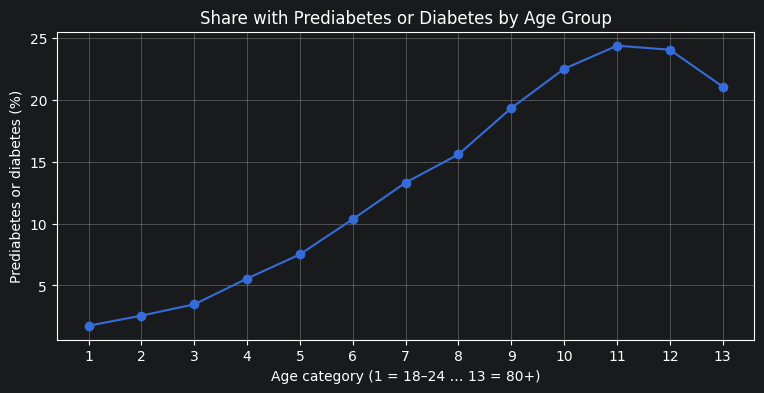

In [23]:
age_rate = df.groupby("Age")["Diabetes_012"].apply(lambda s: (s > 0).mean())

plt.figure()
plt.plot(age_rate.index, age_rate.values * 100, marker="o")
plt.title("Share with Prediabetes or Diabetes by Age Group")
plt.xlabel("Age category (1 = 18–24 … 13 = 80+)")
plt.ylabel("Prediabetes or diabetes (%)")
plt.xticks(range(1, 14))
plt.grid(True)
plt.show()

## 8. Univariate Distributions

Histograms of the numeric variables and bar charts of the ordinal categories show their shape (symmetric or
skewed), typical ranges, and possible extreme values.

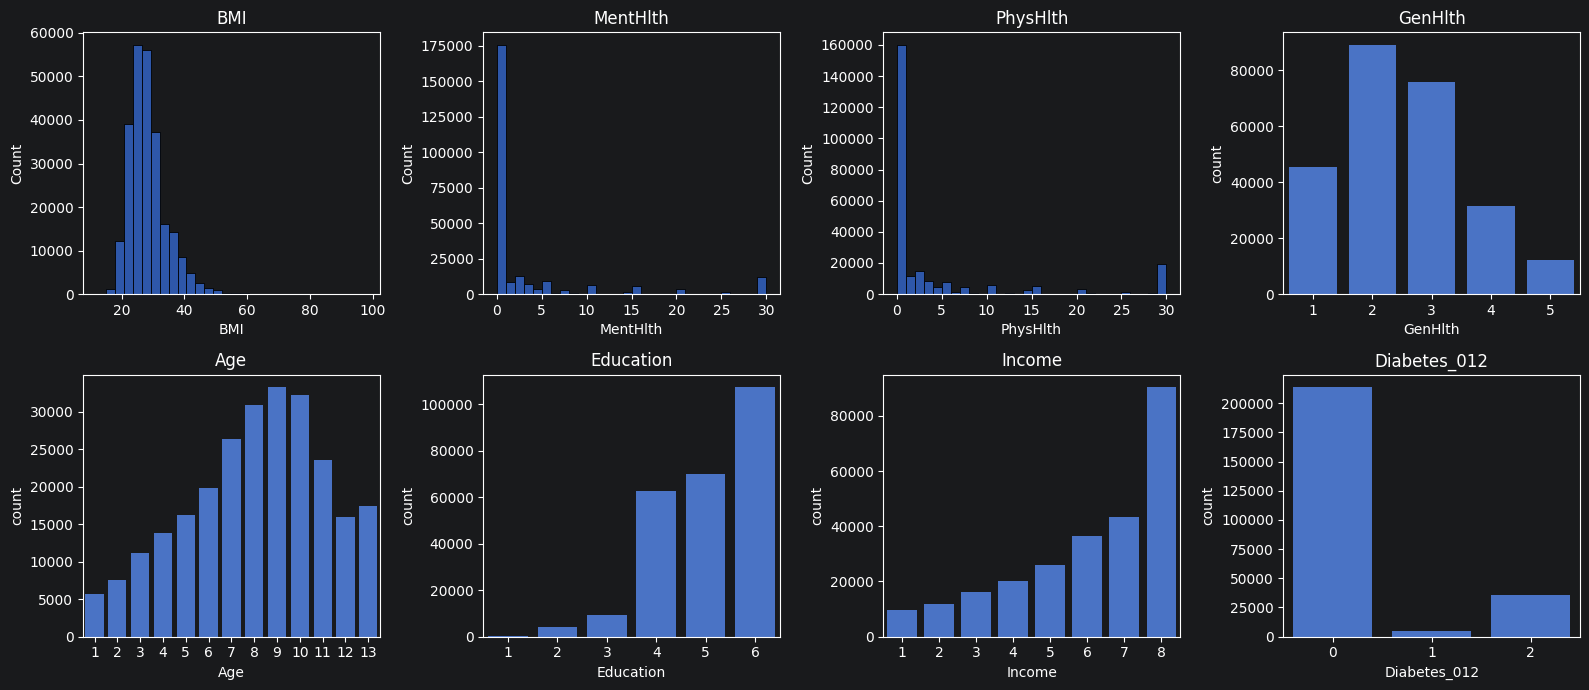

In [24]:
dist_cols = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income", "Diabetes_012"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, dist_cols):
    if col in ["BMI", "MentHlth", "PhysHlth"]:
        sns.histplot(df[col], bins=30, ax=ax)
    else:
        sns.countplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()